# 11 — Stealing-Guided Synonym Substitution: Position Selection

**Main question:** should we select words for substitution by their **original WM association score** rather than by the **difference between original and replacement scores**?

We separate two decisions:

1. **Which word positions to modify?** Original V1 uses maximal gain `score(original) − score(best_synonym)`; the new method uses maximal `score(original)` only.
2. **Which synonym to use?** Guided selects the lowest WM-score WordNet synonym with sufficient training support. Random draws uniformly from all single-word WordNet synonyms.

### Experimental protocol

- **10 stratified train/test splits**: 400 matched WM/NoWM training pairs, 200 held-out watermarked test texts.
- **Four minimum-support thresholds**: `2, 5, 10, 15`.
- **Five nominal substitution budgets**: `10%, 20%, 30%, 40%, 50%`.
- **Six methods**: original gain positions + guided synonym, original gain positions + random synonym, **new score positions + guided synonym**, **new score positions + random synonym**, fully random baseline, existing MarkLLM reproduction.
- **Controlled position comparison**: Both position-ranking approaches share **exactly the same dictionary of eligible original words**, built using the training set. Thus, their *actual* edit count per text is identical; only the position ranking changes.
- MarkLLM is compared on the same held-out samples, at the same *nominal* ratios; its actual edit budget may differ.

**Important limitation:** To isolate position ranking, a source word must already have a supported, lower-score WordNet synonym (the original V1 eligibility rule). Thus synonym information restricts **eligibility**, but **does not determine the new score-based ranking**. Relaxing that restriction would be a separate experiment. Semantic preservation is not enforced. All split results are exploratory, and the 10 splits overlap.

This notebook reads saved results from **notebook 10** and only computes the two new score-ranked methods. Nothing in notebook 09/10 is overwritten. Outputs are checkpointed after each support × split combination. Run with the **local CPU `.venv`**; no 8B model or A100 is needed.

## 1. Imports, paths, and locked configuration

In [1]:
import hashlib
import json
import math
import random
import re
import sys
import time
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import wordnet
from tqdm import tqdm


def find_project_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "detection.py").is_file() and (
            folder / "results" / "Cleaned Data"
        ).is_dir():
            return folder
    raise FileNotFoundError("Cannot find project root (src/detection.py and results/Cleaned Data).")


ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT / "src"))
from detection import detect, load_detector, load_jsonl, save_jsonl

SPLIT_SEEDS = [42, 100, 101, 102, 103, 104, 105, 106, 107, 108]
RATIOS = [0.1, 0.2, 0.3, 0.4, 0.5]
MIN_SUPPORTS = [2, 5, 10, 15]
ALPHA = 0.5
VERSION = "v1_position_ranking_score_vs_gain_2026_11"

METHODS = [
    "gain_guided",
    "gain_random_synonyms",
    "score_guided",
    "score_random_synonyms",
    "fully_random",
    "markllm",
]
NEW_METHODS = ["score_guided", "score_random_synonyms"]

PREV_DIR = (ROOT / "results" / "attacks" / "stealing_guided_v1_improvements"
            / "support_sweep_2_5_10_15")
OUT_DIR = (ROOT / "results" / "attacks" / "stealing_guided_position_selection")
SPLITS_DIR = OUT_DIR / "splits"
WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")

try:
    assert len(wordnet.synsets("important")) > 0
except LookupError as exc:
    raise RuntimeError("NLTK WordNet is missing in the selected Python environment.") from exc

print("Root:", ROOT)
print("Existing notebook 10 results:", PREV_DIR)
print("New results:", OUT_DIR)
print("Splits:", len(SPLIT_SEEDS), "| thresholds:", MIN_SUPPORTS, "| ratios:", RATIOS)

Root: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Existing notebook 10 results: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15
New results: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection
Splits: 10 | thresholds: [2, 5, 10, 15] | ratios: [0.1, 0.2, 0.3, 0.4, 0.5]


## 2. Load paired data, local detector baseline, and MarkLLM data

In [2]:
WM_PATH = ROOT / "results" / "Cleaned Data" / "watermarked_600.jsonl"
NOWM_PATH = ROOT / "results" / "Cleaned Data" / "unwatermarked_600.jsonl"
BASELINE_PATH = ROOT / "results" / "attacks" / "baseline_original.jsonl"
SYN_DIR = ROOT / "results" / "attacks" / "synonym_substitution"

wm = load_jsonl(WM_PATH)
no_wm = load_jsonl(NOWM_PATH)
baseline_rows = load_jsonl(BASELINE_PATH)
assert len(wm) == len(no_wm) == len(baseline_rows) == 600
baseline_by_idx = {int(row["idx"]): row for row in baseline_rows}
assert set(baseline_by_idx) == set(range(600))


def dataset_id(row):
    return row["dataset_name"].split("_batch_")[0]


groups = defaultdict(list)
for idx in range(600):
    assert wm[idx]["prompt"] == no_wm[idx]["prompt"] == baseline_by_idx[idx]["prompt"]
    assert dataset_id(wm[idx]) == dataset_id(no_wm[idx])
    assert wm[idx]["completion"] and no_wm[idx]["completion"]
    groups[dataset_id(wm[idx])].append(idx)
assert len(groups) == 3 and sorted(map(len, groups.values())) == [200, 200, 200]

markllm_paths = {}
for ratio in RATIOS:
    path = SYN_DIR / f"synonym_substitution_r{ratio:.1f}.jsonl"
    assert path.is_file(), f"Missing MarkLLM results: {path}"
    markllm_paths[ratio] = path

previous_config_path = PREV_DIR / "config.json"
assert previous_config_path.is_file(), (
    "Notebook 10 support sweep must be completed first (missing config.json)."
)
previous_config = json.loads(previous_config_path.read_text(encoding="utf-8"))
assert previous_config["min_supports"] == MIN_SUPPORTS
assert previous_config["split_seeds"] == SPLIT_SEEDS
assert previous_config["ratios"] == RATIOS
assert previous_config["alpha"] == ALPHA
assert previous_config["methods"] == [
    "markllm", "guided", "random_synonyms_guided_positions", "fully_random"
]


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


# Safety: don't reuse old detections if the input data or detector changed.
inputs = [WM_PATH, NOWM_PATH, BASELINE_PATH, ROOT / "src" / "detection.py"]
inputs += [markllm_paths[r] for r in RATIOS]
input_sha256 = {str(p.relative_to(ROOT)): sha256_file(p) for p in inputs}
assert previous_config["input_sha256"] == input_sha256, (
    "Input files differ from notebook 10. Do not reuse old results before checking."
)

OUT_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
config_path = OUT_DIR / "config.json"
config = {
    "version": VERSION,
    "previous_attack_version": previous_config["attack_version"],
    "min_supports": MIN_SUPPORTS,
    "split_seeds": SPLIT_SEEDS,
    "ratios": RATIOS,
    "alpha": ALPHA,
    "methods": METHODS,
    "input_sha256": input_sha256,
}
if config_path.exists():
    assert json.loads(config_path.read_text(encoding="utf-8")) == config, (
        "Existing experiment config differs. Use a new output folder."
    )
    print("Configuration verified — resuming previous run.")
else:
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
    print("Saved experiment configuration.")

print("Dataset sizes:", {k: len(v) for k, v in sorted(groups.items())})
print("Original WM detections:", sum(bool(x["detected"]) for x in baseline_rows), "/600")
print("Notebook 10 input fingerprints match: OK")

Saved experiment configuration.
Dataset sizes: {'2-1_longform_qa': 200, '2-2_finance_qa': 200, '5-1_alpacafarm': 200}
Original WM detections: 583 /600
Notebook 10 input fingerprints match: OK


## 3. Recreate the exact training splits and WordNet score dictionaries

In [3]:
def make_split(seed: int):
    rng = random.Random(seed)
    train, test = [], []
    for j, (_, original_indices) in enumerate(sorted(groups.items())):
        indices = original_indices.copy()
        rng.shuffle(indices)
        n_train = 134 if j == 0 else 133
        train.extend(indices[:n_train])
        test.extend(indices[n_train:])
    train, test = sorted(train), sorted(test)
    assert len(train) == 400 and len(test) == 200
    assert set(train).isdisjoint(test)
    assert set(train).union(test) == set(range(600))
    return train, test


def tokenize_words(text: str):
    return WORD_PATTERN.findall(text.lower())


@lru_cache(maxsize=None)
def get_synonyms(word: str):
    candidates = set()
    for synset in wordnet.synsets(word):
        for lemma in synset.lemmas():
            candidate = lemma.name().lower()
            if candidate != word and re.fullmatch(r"[a-z]+", candidate):
                candidates.add(candidate)
    return tuple(sorted(candidates))


def learn_statistics(train_ids):
    wm_counts, no_counts = Counter(), Counter()
    for idx in train_ids:
        wm_counts.update(tokenize_words(wm[idx]["completion"]))
        no_counts.update(tokenize_words(no_wm[idx]["completion"]))
    vocabulary = set(wm_counts) | set(no_counts)
    v = len(vocabulary)
    total_wm, total_no = sum(wm_counts.values()), sum(no_counts.values())
    scores = {
        word: math.log(
            ((wm_counts[word] + ALPHA) / (total_wm + ALPHA * v))
            / ((no_counts[word] + ALPHA) / (total_no + ALPHA * v))
        )
        for word in vocabulary
    }
    return wm_counts, no_counts, scores


def build_dictionary(statistics, min_support):
    wm_counts, no_counts, scores = statistics
    dictionary = {}
    for word in sorted(scores):
        if wm_counts[word] + no_counts[word] < min_support or scores[word] <= 0:
            continue
        candidates = [
            syn for syn in get_synonyms(word)
            if syn in scores
            and wm_counts[syn] + no_counts[syn] >= min_support
            and scores[syn] < scores[word]
        ]
        if not candidates:
            continue
        best = min(candidates, key=lambda s: scores[s])
        dictionary[word] = {
            "replacement": best,
            "original_score": scores[word],
            "replacement_score": scores[best],
            "gain": scores[word] - scores[best],
        }
    return dictionary


train_42, test_42 = make_split(42)
stats_42 = learn_statistics(train_42)
dict_42 = build_dictionary(stats_42, 10)
assert sum(bool(baseline_by_idx[idx]["detected"]) for idx in test_42) == 195
print("Seed 42 | train/test:", len(train_42), len(test_42))
print("Seed 42 | dictionary size at MIN_SUPPORT=10:", len(dict_42))
print("Seed 42 | initial WM detections among test:", 195)

Seed 42 | train/test: 400 200
Seed 42 | dictionary size at MIN_SUPPORT=10: 554
Seed 42 | initial WM detections among test: 195


## 4. Two position rankings, two synonym strategies

In [4]:
def apply_substitutions(text: str, selected):
    attacked = text
    for item in sorted(selected, key=lambda x: x["start"], reverse=True):
        surface = attacked[item["start"]:item["end"]]
        replacement = item["replacement"]
        if surface.isupper():
            replacement = replacement.upper()
        elif surface.istitle():
            replacement = replacement.capitalize()
        attacked = (attacked[:item["start"]] + replacement
                    + attacked[item["end"]:])
    return attacked


def rank_positions(text: str, dictionary: dict, ratio: float, rank_by: str):
    """Select positions from the SAME eligible candidate set.

    rank_by='gain' uses the original V1 criterion.
    rank_by='wm_score' ranks only by the original word's WM score.
    """
    assert rank_by in ("gain", "wm_score")
    matches = list(WORD_PATTERN.finditer(text.lower()))
    candidates = []
    for match in matches:
        word = match.group()
        if word in dictionary:
            information = dictionary[word]
            candidates.append({
                "start": match.start(), "end": match.end(),
                "original": word,
                "replacement": information["replacement"],
                "original_score": information["original_score"],
                "gain": information["gain"],
            })
    # Stable ties in text order, identical to the original V1 ranking behavior.
    key = "gain" if rank_by == "gain" else "original_score"
    candidates.sort(key=lambda r: r[key], reverse=True)
    target = round(len(matches) * ratio)
    selected = candidates[:target]
    return {
        "attacked": apply_substitutions(text, selected),
        "n_words": len(matches),
        "n_covered": len(candidates),
        "n_targeted": target,
        "n_replaced": len(selected),
        "substitutions": selected,
    }


def random_synonyms_same_positions(text: str, selected_result: dict, seed: int):
    rng = random.Random(seed)
    selected = []
    for item in selected_result["substitutions"]:
        options = get_synonyms(item["original"])
        assert options, item["original"]
        selected.append({
            "start": item["start"], "end": item["end"],
            "original": item["original"],
            "replacement": rng.choice(options),
        })
    return {
        "attacked": apply_substitutions(text, selected),
        "n_words": selected_result["n_words"],
        "n_covered": selected_result["n_covered"],
        "n_targeted": selected_result["n_targeted"],
        "n_replaced": len(selected),
        "substitutions": selected,
    }


def attack_seed(split_seed: int, ratio_index: int, idx: int, method_offset: int):
    # Same stream as the original notebook 10 for the random-synonyms control.
    return split_seed * 10_000_000 + ratio_index * 1_000_000 + idx * 10 + method_offset


# Sanity check: identical dictionary candidate coverage and budget, different ranking.
example_text = wm[test_42[0]]["completion"]
for ratio in RATIOS:
    old_rank = rank_positions(example_text, dict_42, ratio, "gain")
    new_rank = rank_positions(example_text, dict_42, ratio, "wm_score")
    assert old_rank["n_replaced"] == new_rank["n_replaced"]
    assert old_rank["n_covered"] == new_rank["n_covered"]
    assert all(i["original_score"] > 0 for i in new_rank["substitutions"])
print("Position-selection sanity checks: OK")

Position-selection sanity checks: OK


## 5. Verify that our implementation reproduces the saved original gain-ranked results

In [5]:
# We do not re-run the old attack: verify one saved split against our reimplementation.
old_file = PREV_DIR / "splits" / "support_10" / "split_42.jsonl"
assert old_file.is_file(), f"Missing notebook 10 checkpoint: {old_file}"
old_rows = load_jsonl(old_file)
old_lookup = {(float(r["ratio"]), int(r["idx"]), r["method"]): r for r in old_rows}
assert len(old_lookup) == 5 * 200 * 4

for idx in test_42:
    text = wm[idx]["completion"]
    for ratio in RATIOS:
        expected = old_lookup[(ratio, idx, "guided")]
        actual = rank_positions(text, dict_42, ratio, rank_by="gain")
        assert actual["attacked"] == expected["attacked"], (ratio, idx)
        assert actual["n_replaced"] == expected["n_replaced"]

print("Old gain-ranked attack reproduced exactly: 200 texts × 5 ratios (support=10, split=42).")
print("New score-ranked positions are compared on this same eligible candidate set.")

Old gain-ranked attack reproduced exactly: 200 texts × 5 ratios (support=10, split=42).
New score-ranked positions are compared on this same eligible candidate set.


## 6. Generate and detect **only the two new score-ranked methods**

In [6]:
# No 8B model: same tokenizer and detector as notebook 09/10.
tokenizer, detector = load_detector(ROOT)


def run_new_split(support: int, seed: int):
    train_ids, test_ids = make_split(seed)
    dictionary = build_dictionary(learn_statistics(train_ids), support)
    rows = []

    for ratio_index, ratio in enumerate(RATIOS):
        for idx in tqdm(test_ids, desc=f"support={support}, split={seed}, ratio={ratio:.1f}", leave=False):
            text = wm[idx]["completion"]
            selected = rank_positions(text, dictionary, ratio, "wm_score")
            random_result = random_synonyms_same_positions(
                text, selected,
                seed=attack_seed(seed, ratio_index, idx, 1),
            )
            assert selected["n_replaced"] == random_result["n_replaced"]
            base = {
                "min_support": support, "split_seed": seed,
                "ratio": ratio, "idx": idx, "dataset": dataset_id(wm[idx]),
                "original_detected": bool(baseline_by_idx[idx]["detected"]),
                "dictionary_size": len(dictionary),
                "n_words": selected["n_words"],
                "n_covered": selected["n_covered"],
                "n_targeted": selected["n_targeted"],
                "n_replaced": selected["n_replaced"],
            }
            for method, result in (
                ("score_guided", selected),
                ("score_random_synonyms", random_result),
            ):
                evaluation = detect(result["attacked"], tokenizer, detector)
                rows.append({
                    **base, "method": method,
                    "detected": bool(evaluation["detected"]),
                    "p_value": float(evaluation["p_value"]),
                    "green_fraction": evaluation.get("green_fraction"),
                    "n_scored": evaluation.get("n_scored"),
                    "n_tokens": evaluation.get("n_tokens"),
                    "attacked": result["attacked"],
                })
    return rows


def validate_new_split(rows, support, seed):
    _, test_ids = make_split(seed)
    assert len(rows) == 200 * len(RATIOS) * 2
    keys = {(float(r["ratio"]), int(r["idx"]), r["method"]) for r in rows}
    assert len(keys) == len(rows)
    assert {int(r["idx"]) for r in rows} == set(test_ids)
    assert {float(r["ratio"]) for r in rows} == set(RATIOS)
    assert {r["method"] for r in rows} == set(NEW_METHODS)
    assert all(r["split_seed"] == seed and r["min_support"] == support for r in rows)
    return True


def save_checkpoint(rows, path: Path):
    if path.exists():
        raise FileExistsError(f"Refusing to overwrite checkpoint: {path}")
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        tmp.unlink()  # A previous interrupted write; never a completed checkpoint.
    save_jsonl(rows, tmp)
    tmp.rename(path)


print("Ready: only two new methods need detector evaluations.")

/Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ready: only two new methods need detector evaluations.


## 7. Execute all supports and splits (automatic checkpoint / resume)

In [7]:
start_time = time.perf_counter()
new_checkpoint_files = []

for support in MIN_SUPPORTS:
    folder = SPLITS_DIR / f"support_{support}"
    folder.mkdir(parents=True, exist_ok=True)
    for seed in SPLIT_SEEDS:
        path = folder / f"split_{seed}.jsonl"
        if path.exists():
            rows = load_jsonl(path)
            validate_new_split(rows, support, seed)
            print(f"support {support} | split {seed}: checkpoint reused")
        else:
            rows = run_new_split(support, seed)
            validate_new_split(rows, support, seed)
            save_checkpoint(rows, path)
            print(f"support {support} | split {seed}: computed and saved")
        new_checkpoint_files.append(path)

assert len(new_checkpoint_files) == len(MIN_SUPPORTS) * len(SPLIT_SEEDS)
print("\nCompleted:", len(new_checkpoint_files), "checkpoints")
print(f"Elapsed this run: {time.perf_counter() - start_time:.1f} seconds")
print("Results saved:", SPLITS_DIR)

Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_42.jsonl.temporary
support 2 | split 42: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_100.jsonl.temporary
support 2 | split 100: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_101.jsonl.temporary
support 2 | split 101: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_102.jsonl.temporary
support 2 | split 102: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_103.jsonl.temporary
support 2 | split 103: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_2/split_104.jsonl.temporary
support 2 | split 104: computed and saved


... (30 outputs left out)

Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_15/split_105.jsonl.temporary
support 15 | split 105: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_15/split_106.jsonl.temporary
support 15 | split 106: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_15/split_107.jsonl.temporary
support 15 | split 107: computed and saved


Saved 2000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits/support_15/split_108.jsonl.temporary
support 15 | split 108: computed and saved

Completed: 40 checkpoints
Elapsed this run: 66.4 seconds
Results saved: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/splits


## 8. Combine saved notebook-10 results and new results, and check identical budgets

In [8]:
OLD_TO_NEW = {
    "guided": "gain_guided",
    "random_synonyms_guided_positions": "gain_random_synonyms",
    "fully_random": "fully_random",
    "markllm": "markllm",
}


def check_old_split(rows, support: int, seed: int):
    _, test_ids = make_split(seed)
    assert len(rows) == 200 * len(RATIOS) * 4
    assert len({(r["ratio"], r["idx"], r["method"]) for r in rows}) == len(rows)
    assert {r["idx"] for r in rows} == set(test_ids)
    assert {r["method"] for r in rows} == set(OLD_TO_NEW)
    assert all(r["min_support"] == support and r["split_seed"] == seed for r in rows)
    return True


summary_rows = []
dataset_rows = []
paired_differences = []

for support in MIN_SUPPORTS:
    for seed in SPLIT_SEEDS:
        _, test_ids = make_split(seed)
        eligible_ids = {i for i in test_ids if bool(baseline_by_idx[i]["detected"])}
        old_path = PREV_DIR / "splits" / f"support_{support}" / f"split_{seed}.jsonl"
        new_path = SPLITS_DIR / f"support_{support}" / f"split_{seed}.jsonl"
        assert old_path.exists() and new_path.exists(), (old_path, new_path)
        old = load_jsonl(old_path)
        new = load_jsonl(new_path)
        check_old_split(old, support, seed)
        validate_new_split(new, support, seed)

        # Map only the existing row metadata, avoiding repeated storage of attacked text.
        by_key = {}
        for row in old:
            key = (float(row["ratio"]), int(row["idx"]), OLD_TO_NEW[row["method"]])
            by_key[key] = row
        for row in new:
            key = (float(row["ratio"]), int(row["idx"]), row["method"])
            assert key not in by_key
            by_key[key] = row
        assert len(by_key) == len(RATIOS) * 200 * len(METHODS)

        for ratio in RATIOS:
            # For a given source text, both position rankings have identical eligible
            # vocabulary and thus identical actual edit budgets; random baselines too.
            for idx in test_ids:
                row_by_method = {m: by_key[(ratio, idx, m)] for m in METHODS}
                counts = [row_by_method[m]["n_replaced"] for m in METHODS if m != "markllm"]
                assert counts[0] == counts[1] == counts[2] == counts[3] == counts[4], (
                    support, seed, ratio, idx, counts
                )
                assert all(bool(r["original_detected"]) == (idx in eligible_ids)
                           for r in row_by_method.values())
                assert len({r["n_covered"] for r in row_by_method.values()}) == 1
                assert len({r["n_words"] for r in row_by_method.values()}) == 1

            for method in METHODS:
                subset = [by_key[(ratio, idx, method)] for idx in test_ids]
                eligible_subset = [r for r in subset if r["idx"] in eligible_ids]
                successes = sum(not bool(r["detected"]) for r in eligible_subset)
                count_words = sum(r["n_words"] for r in subset)
                count_covered = sum(r["n_covered"] for r in subset)
                n_real = (sum(int(r["n_replaced"]) for r in subset)
                          if method != "markllm" else None)
                summary_rows.append({
                    "min_support": support, "split_seed": seed,
                    "ratio": ratio, "method": method,
                    "eligible_n": len(eligible_ids), "successes": successes,
                    "asr": successes / len(eligible_ids),
                    "test_n": len(test_ids),
                    "dictionary_size": subset[0]["dictionary_size"],
                    "dictionary_coverage": count_covered / count_words,
                    "n_real_substitutions": n_real,
                    "actual_edit_ratio": n_real / count_words if n_real is not None else np.nan,
                    "texts_below_budget": (
                        sum(r["n_covered"] < r["n_targeted"] for r in subset)
                        if method != "markllm" else np.nan
                    ),
                })
                for dataset in sorted(groups):
                    ds_rows = [r for r in eligible_subset if r["dataset"] == dataset]
                    if ds_rows:
                        dataset_rows.append({
                            "min_support": support, "split_seed": seed,
                            "ratio": ratio, "method": method,
                            "dataset": dataset, "eligible_n": len(ds_rows),
                            "successes": sum(not bool(r["detected"]) for r in ds_rows),
                            "asr": sum(not bool(r["detected"]) for r in ds_rows) / len(ds_rows),
                        })

            # For future paired tests: retain successes per text without storing text.
            for idx in eligible_ids:
                row = {"min_support": support, "split_seed": seed,
                       "ratio": ratio, "idx": idx}
                for method in METHODS:
                    row[f"success_{method}"] = int(not bool(by_key[(ratio, idx, method)]["detected"]))
                paired_differences.append(row)

summary_df = pd.DataFrame(summary_rows)
dataset_df = pd.DataFrame(dataset_rows)
paired_df = pd.DataFrame(paired_differences)
assert len(summary_df) == len(MIN_SUPPORTS) * len(SPLIT_SEEDS) * len(RATIOS) * len(METHODS)


def export_csv_consistently(df: pd.DataFrame, path: Path, key_columns):
    """Never silently replace a different completed file."""
    if path.exists():
        previous = pd.read_csv(path)
        a = previous.sort_values(key_columns).reset_index(drop=True)
        b = df.sort_values(key_columns).reset_index(drop=True)
        pd.testing.assert_frame_equal(a, b, check_dtype=False, rtol=1e-9, atol=1e-9)
        print("Verified existing file:", path.name)
    else:
        df.to_csv(path, index=False)
        print("Saved:", path.name)


export_csv_consistently(summary_df, OUT_DIR / "position_selection_summary.csv",
                        ["min_support", "split_seed", "ratio", "method"])
export_csv_consistently(dataset_df, OUT_DIR / "position_selection_by_dataset.csv",
                        ["min_support", "split_seed", "ratio", "method", "dataset"])
export_csv_consistently(paired_df, OUT_DIR / "position_selection_paired_successes.csv",
                        ["min_support", "split_seed", "ratio", "idx"])
print("\nSummary configurations:", len(summary_df))
print("Paired eligible-text observations (overlapping across splits):", len(paired_df))

Saved: position_selection_summary.csv
Saved: position_selection_by_dataset.csv
Saved: position_selection_paired_successes.csv

Summary configurations: 1200
Paired eligible-text observations (overlapping across splits): 38800


## 9. Results — mean ASR, edits, and saturation by support

In [9]:
stats_df = (
    summary_df.groupby(["min_support", "ratio", "method"], as_index=False)
    .agg(mean_asr=("asr", "mean"), std_asr=("asr", "std"),
         min_asr=("asr", "min"), max_asr=("asr", "max"),
         actual_edit_ratio=("actual_edit_ratio", "mean"),
         mean_dictionary_size=("dictionary_size", "mean"),
         coverage=("dictionary_coverage", "mean"),
         texts_below_budget=("texts_below_budget", "mean"))
)
export_csv_consistently(stats_df, OUT_DIR / "position_selection_statistics.csv",
                        ["min_support", "ratio", "method"])

for support in MIN_SUPPORTS:
    part = stats_df[stats_df["min_support"] == support]
    print(f"\n=== MIN_SUPPORT = {support} — mean ASR (%) on 10 overlapping splits ===")
    asr_table = part.pivot(index="ratio", columns="method", values="mean_asr") * 100
    display(asr_table.round(2))

    budget = part[part["method"] == "score_guided"][
        ["ratio", "actual_edit_ratio", "coverage", "texts_below_budget"]].copy()
    budget[["actual_edit_ratio", "coverage"]] *= 100
    print("Actual edits and dictionary coverage (%, texts below budget / 200):")
    display(budget.round(2).reset_index(drop=True))

print("Reminder: MarkLLM ratios are NOMINAL; effective edit budgets are not verified.")

Saved: position_selection_statistics.csv

=== MIN_SUPPORT = 2 — mean ASR (%) on 10 overlapping splits ===


method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.93,6.40,6.40,3.92,6.34,6.71
0.2,11.75,19.35,20.12,8.61,19.91,20.53
0.3,21.00,29.21,31.25,18.61,29.62,31.31
0.4,23.18,30.55,33.22,32.89,30.50,32.40
0.5,22.29,30.55,33.43,56.24,30.55,32.83


Actual edits and dictionary coverage (%, texts below budget / 200):


,ratio,actual_edit_ratio,coverage,texts_below_budget
0,0.1,9.99,24.29,0.9
1,0.2,19.30,24.29,45.8
2,0.3,23.72,24.29,164.9
3,0.4,24.27,24.29,198.1
4,0.5,24.29,24.29,199.8



=== MIN_SUPPORT = 5 — mean ASR (%) on 10 overlapping splits ===


method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.82,6.45,6.34,3.92,6.08,7.27
0.2,10.72,16.93,18.98,8.61,17.80,19.28
0.3,16.51,22.86,25.73,18.61,23.17,26.00
0.4,17.23,24.05,26.81,32.89,24.05,25.79
0.5,17.64,24.10,27.29,56.24,24.10,26.40


... (7 outputs left out)

method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.88,6.65,6.76,3.92,6.09,6.19
0.2,8.45,12.69,14.38,8.61,12.69,13.40
0.3,10.30,15.16,15.67,18.61,15.01,17.06
0.4,11.60,15.11,16.42,32.89,15.11,16.09
0.5,10.83,15.11,15.73,56.24,15.11,16.44


Actual edits and dictionary coverage (%, texts below budget / 200):


,ratio,actual_edit_ratio,coverage,texts_below_budget
0,0.1,9.82,17.24,16.6
1,0.2,16.11,17.24,142.1
2,0.3,17.21,17.24,195.3
3,0.4,17.24,17.24,200.0
4,0.5,17.24,17.24,200.0


Reminder: MarkLLM ratios are NOMINAL; effective edit budgets are not verified.


## 10. Direct contrasts: does score-based position ranking beat gain-based ranking?

In [10]:
paired_asr = summary_df.pivot(
    index=["min_support", "split_seed", "ratio"],
    columns="method", values="asr",
)
CONTRASTS = {
    "score_guided - gain_guided": paired_asr["score_guided"] - paired_asr["gain_guided"],
    "score_random - gain_random": paired_asr["score_random_synonyms"] - paired_asr["gain_random_synonyms"],
    "score_random - fully_random": paired_asr["score_random_synonyms"] - paired_asr["fully_random"],
    "score_guided - score_random": paired_asr["score_guided"] - paired_asr["score_random_synonyms"],
    "score_guided - markllm": paired_asr["score_guided"] - paired_asr["markllm"],
}
contrast_rows = []
for support in MIN_SUPPORTS:
    for ratio in RATIOS:
        for title, differences in CONTRASTS.items():
            vals = differences.xs((support, ratio), level=("min_support", "ratio"))
            contrast_rows.append({
                "min_support": support, "ratio": ratio, "contrast": title,
                "mean_difference_pp": vals.mean() * 100,
                "std_difference_pp": vals.std(ddof=1) * 100,
                "positive_splits": int((vals > 0).sum()),
                "ties": int((vals == 0).sum()),
            })
contrast_df = pd.DataFrame(contrast_rows)
export_csv_consistently(contrast_df, OUT_DIR / "position_selection_contrasts.csv",
                        ["min_support", "ratio", "contrast"])

print("=== Position ranking comparison: score-guided vs gain-guided ===")
display(contrast_df[contrast_df["contrast"] == "score_guided - gain_guided"]
        .round(2).reset_index(drop=True))

print("\n=== Score-ranked positions with random synonyms vs gain-ranked positions ===")
display(contrast_df[contrast_df["contrast"] == "score_random - gain_random"]
        .round(2).reset_index(drop=True))

print("Descriptive only: overlapping splits, multiple configurations, and no held-out tuning.")

Saved: position_selection_contrasts.csv
=== Position ranking comparison: score-guided vs gain-guided ===


,min_support,ratio,contrast,mean_difference_pp,std_difference_pp,positive_splits,ties
0,2,0.1,score_guided - gain_guided,-0.05,1.47,5,1
1,2,0.2,score_guided - gain_guided,0.55,2.23,6,0
2,2,0.3,score_guided - gain_guided,0.41,0.72,6,3
3,2,0.4,score_guided - gain_guided,-0.05,0.16,0,9
4,2,0.5,score_guided - gain_guided,0.00,0.00,0,10
5,5,0.1,score_guided - gain_guided,-0.37,1.78,5,1
6,5,0.2,score_guided - gain_guided,0.88,1.14,7,1
7,5,0.3,score_guided - gain_guided,0.31,0.56,6,2
8,5,0.4,score_guided - gain_guided,0.00,0.00,0,10
9,5,0.5,score_guided - gain_guided,0.00,0.00,0,10



=== Score-ranked positions with random synonyms vs gain-ranked positions ===


,min_support,ratio,contrast,mean_difference_pp,std_difference_pp,positive_splits,ties
0,2,0.1,score_random - gain_random,0.31,1.40,4,3
1,2,0.2,score_random - gain_random,0.41,2.44,5,0
2,2,0.3,score_random - gain_random,0.06,3.84,4,0
3,2,0.4,score_random - gain_random,-0.82,3.04,3,0
4,2,0.5,score_random - gain_random,-0.60,2.87,5,0
5,5,0.1,score_random - gain_random,0.93,1.62,5,1
6,5,0.2,score_random - gain_random,0.30,2.84,5,0
7,5,0.3,score_random - gain_random,0.26,2.16,7,0
8,5,0.4,score_random - gain_random,-1.02,3.04,4,0
9,5,0.5,score_random - gain_random,-0.89,2.07,4,0


Descriptive only: overlapping splits, multiple configurations, and no held-out tuning.


## 11. Coverage and selection overlap (diagnostic)

In [11]:
# Compute this diagnostic without any detector or watermark key.
# At high ratios, both rankings can select every eligible position and become identical.
overlap_rows = []
for support in MIN_SUPPORTS:
    for seed in SPLIT_SEEDS:
        train_ids, test_ids = make_split(seed)
        dictionary = build_dictionary(learn_statistics(train_ids), support)
        for ratio in RATIOS:
            common = selected_new = selected_old = 0
            all_words = 0
            for idx in test_ids:
                text = wm[idx]["completion"]
                a = rank_positions(text, dictionary, ratio, "gain")
                b = rank_positions(text, dictionary, ratio, "wm_score")
                posa = {(r["start"], r["end"]) for r in a["substitutions"]}
                posb = {(r["start"], r["end"]) for r in b["substitutions"]}
                assert len(posa) == len(posb)
                common += len(posa & posb)
                selected_old += len(posa)
                selected_new += len(posb)
                all_words += a["n_words"]
            overlap_rows.append({
                "min_support": support, "split_seed": seed, "ratio": ratio,
                "overlap_of_selected_positions": common / selected_old if selected_old else np.nan,
                "actual_edit_ratio": selected_new / all_words,
            })

ov_df = pd.DataFrame(overlap_rows)
overlap_summary = (ov_df.groupby(["min_support", "ratio"], as_index=False)
                   .agg(mean_position_overlap=("overlap_of_selected_positions", "mean"),
                        mean_actual_edit_ratio=("actual_edit_ratio", "mean")))
export_csv_consistently(overlap_summary, OUT_DIR / "position_selection_overlap.csv",
                        ["min_support", "ratio"])
print("Average proportion of identical selected positions (gain vs original-WM-score):")
display((ov_df.groupby(["ratio", "min_support"])["overlap_of_selected_positions"]
         .mean().unstack() * 100).round(1))

Saved: position_selection_overlap.csv
Average proportion of identical selected positions (gain vs original-WM-score):


min_support,2,5,10,15
ratio,,,,
0.1,59.2,65.2,70.9,75.5
0.2,86.2,90.1,93.9,95.8
0.3,98.4,99.2,99.6,99.9
0.4,99.9,100.0,100.0,100.0
0.5,100.0,100.0,100.0,100.0


## 12. Optional plot (no need for Matplotlib to finish the experiment)

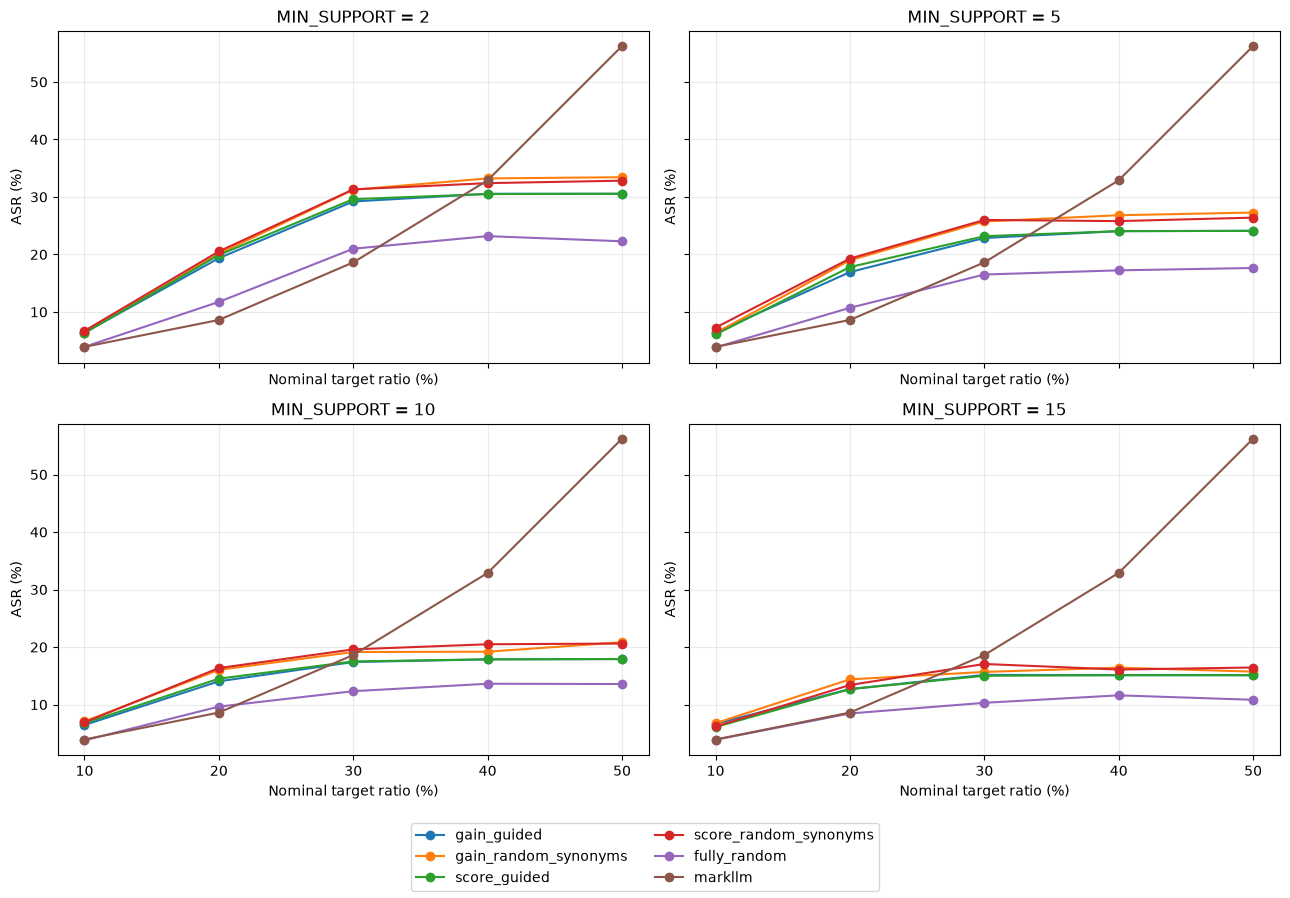

Saved chart: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_position_selection/asr_position_selection.png


In [12]:
try:
    import matplotlib.pyplot as plt
except (ImportError, OSError) as exc:
    print("Chart skipped: Matplotlib / Pillow cannot be imported.")
    print(str(exc)[:250])
else:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
    for ax, support in zip(axes.flat, MIN_SUPPORTS):
        part = stats_df[stats_df["min_support"] == support]
        for method in METHODS:
            sample = part[part["method"] == method].sort_values("ratio")
            ax.plot(sample["ratio"] * 100, sample["mean_asr"] * 100,
                    marker="o", label=method)
        ax.set_title(f"MIN_SUPPORT = {support}")
        ax.set_xlabel("Nominal target ratio (%)")
        ax.set_ylabel("ASR (%)")
        ax.set_xticks([10, 20, 30, 40, 50])
        ax.grid(alpha=0.25)
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc="lower center", ncol=2)
    fig.tight_layout(rect=[0, 0.09, 1, 1])
    path = OUT_DIR / "asr_position_selection.png"
    fig.savefig(path, dpi=150)
    plt.show()
    print("Saved chart:", path)

## 13. How to interpret the results

1. **Primary controlled comparison:** `score_guided` vs `gain_guided`, and `score_random_synonyms` vs `gain_random_synonyms`. The dictionary, candidate positions, dataset, ratios, and actual counts of substitutions are matched. The position **ranking criterion** is what changes.
2. **Effect of synonym scoring:** `score_guided` vs `score_random_synonyms` on **identical selected positions**.
3. **Effect of intelligent positioning:** `score_random_synonyms` vs `fully_random` at equal actual edit counts.
4. **Main external reference:** MarkLLM (`markllm`) at the **same nominal ratio** but **unknown effective number of words edited**. Do not claim edit-budget equivalence without auditing its texts.
5. **Saturation:** beyond the dictionary's coverage, rankings converge and stop producing more edits; check the position-overlap table before interpreting high-ratio ASR.
6. **Statistical validity:** the same prompts occur in multiple overlapping splits, thresholds, and ratios. These are exploratory ablations, not independent replications. Selecting best thresholds from these tests and then claiming an unbiased test ASR would be test-set tuning. Use a separate validation/evaluation design for confirmatory reporting.
7. **Threat model:** no secret watermark key, token greenlist, or detector p-values are consulted to select substitutions. Detection is used for evaluation only. WordNet candidates can change meaning, as with the original reproduced attack.

**Files:** `position_selection_summary.csv`, `position_selection_statistics.csv`, `position_selection_contrasts.csv`, `position_selection_paired_successes.csv`, `position_selection_overlap.csv`, and saved new attack checkpoints under `results/attacks/stealing_guided_position_selection/`.